# DSC 411/511 Project
# Notebook 03: RQ1: Can We Predict a Positive Building Payment?

**Class topics:** Lecture 05 (decision trees, naive Bayes), Lecture 06 (k-NN), Lecture 07 (logistic
regression, SVM, evaluation, ROC, cross-validation, leakage, imbalance), Lecture 14 (neural networks).

---

**Initial question.** *Can policy, building and external event information predict whether a claim receives a
positive building payment (`amountPaidOnBuildingClaim > 0`)?*

This first version has two weak points. Almost any model "predicts" a little, so the answer is always "partly".
And "not paid" mixes very different events ("not actual flood", "below deductible", admin closures, and claims that
are simply still open). Sections 1-14 study the course models on the initial question. Section 15 then answers a
sharper version:

> **RQ1 (refined). Among closed NFIP claims, do flood-hazard facts known at filing time (PRISM rain, HURDAT2 storm,
> coast distance) improve the prediction of a claim closing without building payment, beyond building and policy
> facts alone? And which kinds of non-payment can be predicted?**

- **H1.** Adding event data raises ROC-AUC, PR-AUC and the top-10% lift for "not paid". We accept H1 only if the
  95% confidence interval of the gain, from resampling **whole storms**, is above 0.
- **H2.** Non-payment caused by the flood itself ("not actual flood", "no demonstrable damage", "below
  deductible") is easier to predict than administrative closures.

**Why it matters.** About one claim in five closes with no building payment. Each one still costs an
adjuster visit. If we could tell at filing time which claims will probably not pay, the program could
route them to a faster desk review, and spend field time on the claims that will pay.

**How this notebook moves.** We first study each classifier from the course on this problem, one
at a time, and explain how it decides. Then we compare them, and finally we answer the question
with three feature sets: **NFIP only**, **+ event data**, **+ context data**.

---
# Section 0: Setup

In [1]:
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, roc_curve, precision_recall_curve, classification_report)
import lightgbm as lgb
import shap
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
TARGET = 'building_paid_flag'
train_claims = claims[claims['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_claims = claims[claims['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
print(f'Train (2020-2023): {len(train_claims):,} claims, paid rate {train_claims[TARGET].mean() * 100:.1f}%')
print(f'Test  (2024-2025): {len(test_claims):,} claims, paid rate {test_claims[TARGET].mean() * 100:.1f}%')

Train (2020-2023): 147,642 claims, paid rate 80.7%
Test  (2024-2025): 105,482 claims, paid rate 86.8%


---
# Section 1: The Target and the Baseline

The classes are not balanced: most claims are paid. A model that always says "paid" is right most of the
time and useless. Lecture 07, Section 6: **accuracy is not enough**. We report:

- **ROC-AUC**: the probability that a random paid claim gets a higher score than a random unpaid claim.
  0.5 = coin flip, 1.0 = perfect.
- **PR-AUC for the "not paid" class**: how well we find the minority class. A random model scores the
  share of unpaid claims.
- **Balanced accuracy**: the mean of the recall on each class.

In [2]:
print('Paid rate by year (%):')
print((claims.groupby('loss_year')[TARGET].mean() * 100).round(1).to_string())
majority_accuracy = test_claims[TARGET].mean()
print(f'\nAlways-"paid" baseline accuracy on test: {majority_accuracy * 100:.1f}%')
print(f'Random PR-AUC for the "not paid" class : {(1 - majority_accuracy):.3f}')

Paid rate by year (%):
loss_year
2020    77.3
2021    81.0
2022    81.7
2023    82.5
2024    87.0
2025    85.8

Always-"paid" baseline accuracy on test: 86.8%
Random PR-AUC for the "not paid" class : 0.132


---
# Section 2: Evaluation Design (how we avoid fooling ourselves)

1. **Time split.** Train on 2020-2023, test on 2024-2025. The test storms (Helene, Milton, Debby,
   Francine, Beryl) were never seen in training. This is "time travel" protection (Lecture 07, Section 11).
2. **Event-grouped cross-validation inside the training years.** Claims from one storm are similar to
   each other. A random K-fold would put Ian claims in both train and validation folds and look too good.
   `GroupKFold` keeps each event in one fold only.
3. **Every preprocessing step inside a Pipeline**, fitted on training rows only.
4. **Thresholds are tuned on 2023**, never on the test years.
5. **No leaking columns.** `check_no_leakage` stops the notebook if one slips in.

In [3]:
numeric_A, categorical_A = FEATURE_SETS['A. NFIP only']
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']
for name, (numeric, categorical) in FEATURE_SETS.items():
    check_no_leakage(numeric + categorical)
    print(f'{name:<45} numeric {len(numeric):>3}   categorical {len(categorical)}')

# Smaller samples for the slow, distance-based methods (k-NN, SVM). Same rows for every model.
model_sample_train = train_claims.sample(30_000, random_state=SEED)
model_sample_test = test_claims.sample(20_000, random_state=SEED)
print(f'\nComparison sample: train {len(model_sample_train):,}, test {len(model_sample_test):,}')

A. NFIP only                                  numeric  23   categorical 8
B. NFIP + event (PRISM, HURDAT2, coast)       numeric  35   categorical 8
C. NFIP + event + context (ACS, NRI)          numeric  50   categorical 8

Comparison sample: train 30,000, test 20,000


---
# Section 3: Decision Tree (Lecture 05)

## 3.1 How a tree picks a split, by hand

A tree asks yes/no questions. At each node it tries every feature and every cut point, and keeps
the one that makes the two children **purest**. Purity is measured with **Gini impurity**:

Gini = 1 - p(paid)^2 - p(not paid)^2

Gini is 0 for a pure node and 0.5 for a 50/50 node. The quality of a split is the drop in
Gini, weighted by the size of each child. We compute it by hand for one feature: 3-day rain.

In [4]:
def gini(labels):
    share_paid = labels.mean()
    return 1 - share_paid ** 2 - (1 - share_paid) ** 2


parent = model_sample_train[TARGET]
print(f'Parent node: {len(parent):,} claims, paid {parent.mean() * 100:.1f}%, Gini = {gini(parent):.4f}\n')
split_rows = []
for cut in [5, 10, 20, 40, 60, 100, 150]:
    left = model_sample_train.loc[model_sample_train['rain_3day_mm'] <= cut, TARGET]
    right = model_sample_train.loc[model_sample_train['rain_3day_mm'] > cut, TARGET]
    weighted_child_gini = (len(left) * gini(left) + len(right) * gini(right)) / len(parent)
    split_rows.append({'cut: rain_3day_mm <=': cut, 'left_n': len(left), 'left_paid_%': round(left.mean() * 100, 1),
                       'right_n': len(right), 'right_paid_%': round(right.mean() * 100, 1),
                       'weighted_child_gini': round(weighted_child_gini, 4),
                       'gini_decrease': round(gini(parent) - weighted_child_gini, 4)})
print(pd.DataFrame(split_rows).to_string(index=False))

Parent node: 30,000 claims, paid 80.6%, Gini = 0.3126

 cut: rain_3day_mm <=  left_n  left_paid_%  right_n  right_paid_%  weighted_child_gini  gini_decrease
                    5     979         50.4    29021          81.6               0.3064         0.0062
                   10    1271         49.6    28729          82.0               0.3041         0.0085
                   20    1962         54.4    28038          82.4               0.3029         0.0096
                   40    2978         59.6    27022          82.9               0.3028         0.0097
                   60    4266         65.2    25734          83.2               0.3047         0.0078
                  100    7751         72.6    22249          83.4               0.3081         0.0045
                  150   13743         78.1    16257          82.8               0.3115         0.0011


The best cut is the one with the largest Gini decrease. Claims with very little rain are paid less
often: many of them are "not actual flood" or "below deductible". The tree repeats this search
at every node, for every feature.

## 3.2 Depth and overfitting (Lecture 05, Section 4)

max_depth  train_ROC_AUC  test_ROC_AUC
        2         0.5999        0.5798
        3         0.6597        0.6119
        4         0.6882        0.6420
        6         0.7384        0.6687
        8         0.7705        0.7058
       10         0.8026        0.6845
       14         0.8448        0.6568
       20         0.8664        0.6549
     None         0.8702        0.6544


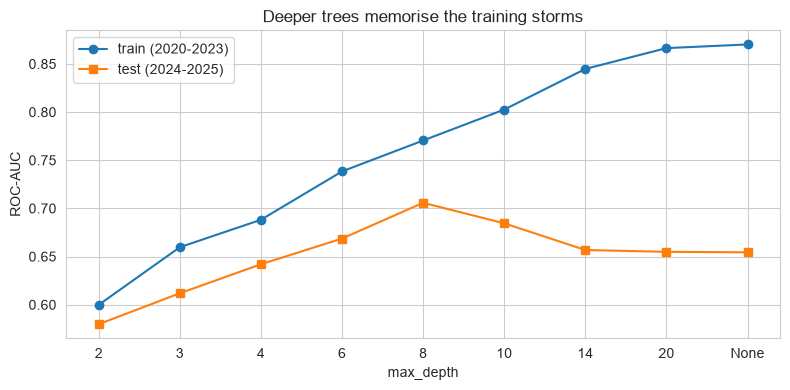

In [5]:
tree_preprocessor = make_preprocessor(numeric_C, categorical_C, scale=False)   # trees do not need scaling
train_matrix_tree = tree_preprocessor.fit_transform(train_claims)
test_matrix_tree = tree_preprocessor.transform(test_claims)
tree_feature_names = list(tree_preprocessor.get_feature_names_out())

depth_rows = []
for depth in [2, 3, 4, 6, 8, 10, 14, 20, None]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=SEED, class_weight='balanced')
    tree.fit(train_matrix_tree, train_claims[TARGET])
    depth_rows.append({'max_depth': str(depth),
                       'train_ROC_AUC': roc_auc_score(train_claims[TARGET], tree.predict_proba(train_matrix_tree)[:, 1]),
                       'test_ROC_AUC': roc_auc_score(test_claims[TARGET], tree.predict_proba(test_matrix_tree)[:, 1])})
depth_table = pd.DataFrame(depth_rows).round(4)
print(depth_table.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depth_table['max_depth'], depth_table['train_ROC_AUC'], 'o-', label='train (2020-2023)')
ax.plot(depth_table['max_depth'], depth_table['test_ROC_AUC'], 's-', label='test (2024-2025)')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC')
ax.set_title('Deeper trees memorise the training storms')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_tree_depth.png', dpi=120)
plt.show()

## 3.3 What a small tree learned

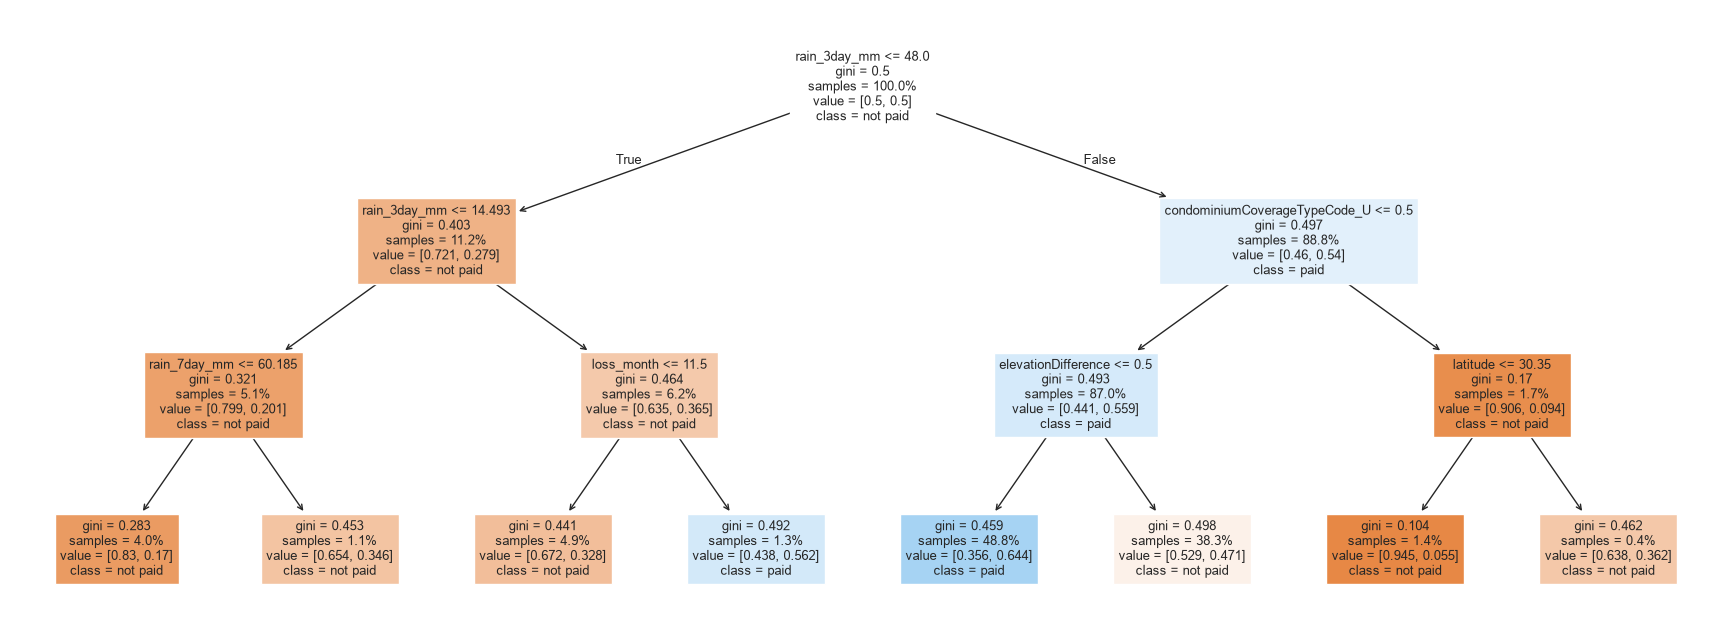

|--- rain_3day_mm <= 48.00
|   |--- rain_3day_mm <= 14.49
|   |   |--- rain_7day_mm <= 60.18
|   |   |   |--- class: 0
|   |   |--- rain_7day_mm >  60.18
|   |   |   |--- class: 0
|   |--- rain_3day_mm >  14.49
|   |   |--- loss_month <= 11.50
|   |   |   |--- class: 0
|   |   |--- loss_month >  11.50
|   |   |   |--- class: 1
|--- rain_3day_mm >  48.00
|   |--- condominiumCoverageTypeCode_U <= 0.50
|   |   |--- elevationDifference <= 0.50
|   |   |   |--- class: 1
|   |   |--- elevationDifference >  0.50
|   |   |   |--- class: 0
|   |--- condominiumCoverageTypeCode_U >  0.50
|   |   |--- latitude <= 30.35
|   |   |   |--- class: 0
|   |   |--- latitude >  30.35
|   |   |   |--- class: 0



In [6]:
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=SEED, class_weight='balanced')
small_tree.fit(train_matrix_tree, train_claims[TARGET])
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(small_tree, feature_names=tree_feature_names, class_names=['not paid', 'paid'], filled=True, fontsize=9,
          proportion=True, impurity=True, ax=ax)
plt.savefig(FIGURE_DIR / '03_small_tree.png', dpi=100)
plt.show()
print(export_text(small_tree, feature_names=tree_feature_names, max_depth=3))

---
# Section 4: Naive Bayes (Lecture 05, Sections 7-8)

Bayes' rule: P(paid | features) is proportional to P(paid) x P(feature 1 | paid) x P(feature 2 | paid) x ...

The **naive** part is the multiplication: it assumes the features are independent inside each class.
`GaussianNB` also assumes each feature is a bell curve inside each class. It stores only a mean and a
variance per feature per class.

In [7]:
nb_preprocessor = make_preprocessor(numeric_C, categorical_C, scale=True)
nb_train = nb_preprocessor.fit_transform(model_sample_train)
nb_test = nb_preprocessor.transform(model_sample_test)
naive_bayes = GaussianNB().fit(nb_train, model_sample_train[TARGET])
nb_names = list(nb_preprocessor.get_feature_names_out())
stored = pd.DataFrame({'mean | not paid': naive_bayes.theta_[0], 'mean | paid': naive_bayes.theta_[1],
                       'var | not paid': naive_bayes.var_[0], 'var | paid': naive_bayes.var_[1]}, index=nb_names)
stored['mean_gap'] = (stored['mean | paid'] - stored['mean | not paid']).abs()
print('What the model stores (scaled units), 8 features with the biggest class gap:')
print(stored.sort_values('mean_gap', ascending=False).head(8).round(3).to_string())
nb_scores = naive_bayes.predict_proba(nb_test)[:, 1]
print(f'\nNaive Bayes test ROC-AUC (sample): {roc_auc_score(model_sample_test[TARGET], nb_scores):.4f}')

What the model stores (scaled units), 8 features with the biggest class gap:
                               mean | not paid  mean | paid  var | not paid  var | paid  mean_gap
postFIRMConstructionIndicator            0.204       -0.049           1.034       0.979     0.253
building_age_at_loss                    -0.194        0.047           0.970       0.996     0.241
in_special_flood_hazard_area            -0.193        0.047           1.217       0.937     0.240
rain_3day_mm                            -0.187        0.045           1.086       0.969     0.232
rain_max_daily_7day_mm                  -0.173        0.042           1.019       0.986     0.215
rain_7day_mm                            -0.166        0.040           1.082       0.972     0.206
longitude                               -0.148        0.036           1.133       0.962     0.183
acs_pct_non_hispanic_white              -0.138        0.033           1.091       0.972     0.172

Naive Bayes test ROC-AUC (sample): 0.622

**Why naive Bayes struggles here.** Rain over 1, 3 and 7 days are strongly correlated, so naive Bayes
counts the same evidence three times. Dollar and rain columns are skewed, not bell-shaped. Both
assumptions from Lecture 05 Section 8 are broken.

---
# Section 5: k-Nearest Neighbours (Lecture 06)

k-NN has no training step. To score a claim it finds the k most similar past claims (by Euclidean
distance on scaled features) and takes the share that were paid. Scaling is required: without it,
coverage in dollars would decide every distance (Lecture 06, Sections 1-2).

In [8]:
knn_rows = []
for k in [5, 15, 51, 151]:
    start = time.time()
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=4).fit(nb_train, model_sample_train[TARGET])
    knn_scores = knn.predict_proba(nb_test)[:, 1]
    knn_rows.append({'k': k, 'test_ROC_AUC': round(roc_auc_score(model_sample_test[TARGET], knn_scores), 4),
                     'seconds_to_predict_20k': round(time.time() - start, 1)})
print(pd.DataFrame(knn_rows).to_string(index=False))

  k  test_ROC_AUC  seconds_to_predict_20k
  5        0.6455                     0.4
 15        0.6825                     0.4
 51        0.6943                     0.4
151        0.6951                     0.5


Small k overfits to single neighbours. Larger k smooths the vote and does better. k-NN is slow at
prediction time (Lecture 06, Section 6): every new claim is compared with all 30,000 stored claims.

---
# Section 6: Logistic Regression (Lecture 07, Section 1)

Add up every feature with a weight, then squash the sum into a probability with the sigmoid:

z = b0 + b1 x1 + b2 x2 + ...      p(paid) = 1 / (1 + e^(-z))

The weights are found by maximising the likelihood of the training labels. Because the features are
scaled, the size of a weight shows how strongly a one-standard-deviation change moves the log-odds.

In [9]:
logistic_pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)),
                              ('model', LogisticRegression(max_iter=3000, C=0.5))])
logistic_pipeline.fit(train_claims, train_claims[TARGET])
logistic_names = logistic_pipeline.named_steps['prep'].get_feature_names_out()
coefficients = pd.Series(logistic_pipeline.named_steps['model'].coef_[0], index=logistic_names)
intercept = logistic_pipeline.named_steps['model'].intercept_[0]

one_claim = test_claims.iloc[[0]]
scaled_row = logistic_pipeline.named_steps['prep'].transform(one_claim)[0]
z_value = intercept + scaled_row @ coefficients.values
print('ONE CLAIM, TRACED END TO END')
print(f'   event: {one_claim["floodEvent"].iloc[0]}, state {one_claim["state"].iloc[0]}, '
      f'3-day rain {one_claim["rain_3day_mm"].iloc[0]:.0f} mm, storm distance {one_claim["storm_distance_km"].iloc[0]:.0f} km')
print(f'STEP 1  z = {intercept:+.3f} (intercept) + sum of weight x value = {z_value:.3f}')
contributions = pd.Series(scaled_row * coefficients.values, index=logistic_names).sort_values(key=abs, ascending=False)
for name, value in contributions.head(5).items():
    print(f'           {value:+.3f} from {name}')
print(f'STEP 2  p = 1 / (1 + e^(-{z_value:.3f})) = {1 / (1 + np.exp(-z_value)):.3f}')
print(f'STEP 3  truth: {"paid" if one_claim[TARGET].iloc[0] == 1 else "not paid"}')

ONE CLAIM, TRACED END TO END
   event: nan, state ME, 3-day rain 43 mm, storm distance 2000 km
STEP 1  z = +0.464 (intercept) + sum of weight x value = 1.430
           -0.847 from storm_category_at_closest
           +0.650 from condominiumCoverageTypeCode_N
           +0.606 from storm_wind_at_closest_kt
           -0.567 from latitude
           -0.480 from has_contents_coverage
STEP 2  p = 1 / (1 + e^(-1.430)) = 0.807
STEP 3  truth: not paid


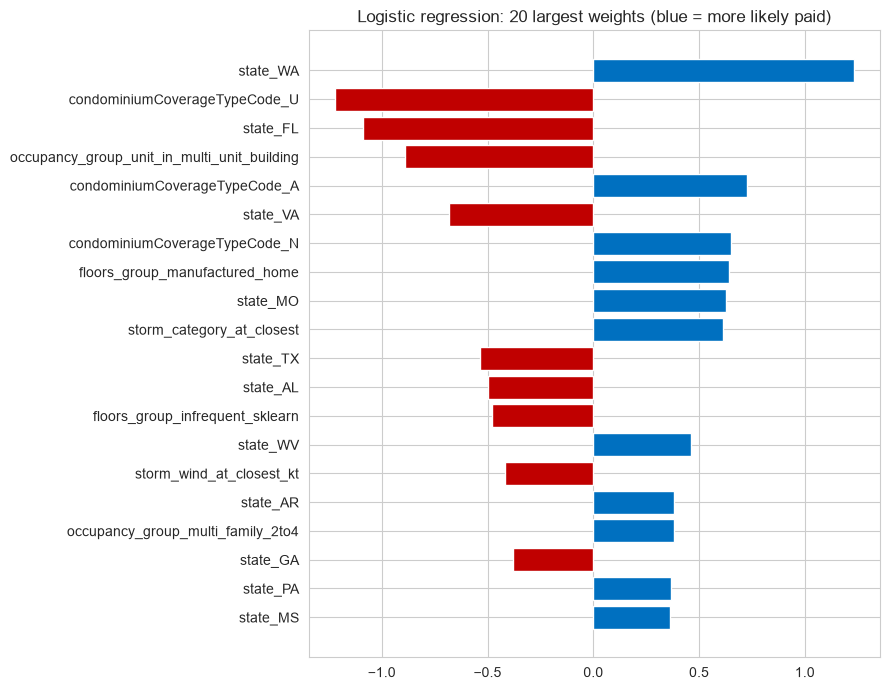

In [10]:
top_coefficients = coefficients.sort_values(key=abs, ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_coefficients.index, top_coefficients.values, color=np.where(top_coefficients.values > 0, '#0070C0', '#C00000'))
ax.set_title('Logistic regression: 20 largest weights (blue = more likely paid)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_logistic_coefficients.png', dpi=120)
plt.show()

---
# Section 7: Support Vector Machine (Lecture 07, Sections 3-4)

An SVM looks for the boundary with the **widest margin** between the classes. Only the claims closest
to the boundary (the support vectors) decide where it goes. With the RBF kernel the boundary can curve.
SVM training grows faster than linearly with the number of rows, so we use the 30,000-row sample.

In [11]:
start = time.time()
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=False, random_state=SEED)
svm_model.fit(nb_train, model_sample_train[TARGET])
svm_scores = svm_model.decision_function(nb_test)
print(f'SVM (RBF) trained in {time.time() - start:.0f} s')
print(f'Support vectors: {svm_model.n_support_.sum():,} of {len(nb_train):,} training claims '
      f'({svm_model.n_support_.sum() / len(nb_train) * 100:.0f}%)')
print(f'SVM test ROC-AUC (sample): {roc_auc_score(model_sample_test[TARGET], svm_scores):.4f}')

SVM (RBF) trained in 309 s
Support vectors: 13,059 of 30,000 training claims (44%)
SVM test ROC-AUC (sample): 0.6963


A large share of the claims are support vectors. That tells us the two classes **overlap heavily**:
many paid and unpaid claims look alike in these features.

---
# Section 8: Neural Network (Lecture 14)

A multi-layer perceptron stacks layers of "weighted sum + non-linear function". It can learn
interactions on its own. Lecture 14's lesson: on tabular data with good columns it often does **not**
beat simpler models. We test that here.

In [12]:
start = time.time()
mlp_pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)),
                         ('model', MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512,
                                                 early_stopping=True, max_iter=60, random_state=SEED))])
mlp_pipeline.fit(train_claims, train_claims[TARGET])
mlp_test_scores = mlp_pipeline.predict_proba(test_claims)[:, 1]
print(f'MLP trained in {time.time() - start:.0f} s, stopped after {mlp_pipeline.named_steps["model"].n_iter_} epochs')
print(f'MLP test ROC-AUC (full test): {roc_auc_score(test_claims[TARGET], mlp_test_scores):.4f}')

MLP trained in 6 s, stopped after 26 epochs
MLP test ROC-AUC (full test): 0.7739


---
# Section 9: Gradient Boosting (LightGBM), one step beyond the course

Boosting builds many small trees **in sequence**. Each new tree is fitted to the errors (the gradient
of the loss) left by the trees before it. The result is a strong model built from weak ones.
LightGBM handles categories and missing values natively and trains fast on 150,000 rows.

In [13]:
def fit_lightgbm(train_rows, numeric, categorical, n_estimators=500):
    model = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, num_leaves=63, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                               random_state=SEED, verbose=-1)
    model.fit(to_category_frame(train_rows, numeric, categorical), train_rows[TARGET])
    return model


lightgbm_C = fit_lightgbm(train_claims, numeric_C, categorical_C)
lightgbm_test_scores = lightgbm_C.predict_proba(to_category_frame(test_claims, numeric_C, categorical_C))[:, 1]
print(f'LightGBM test ROC-AUC (full test): {roc_auc_score(test_claims[TARGET], lightgbm_test_scores):.4f}')

LightGBM test ROC-AUC (full test): 0.7820


---
# Section 10: All Models, One Table (Lecture 06, Section 7: "three methods, one question")

Every model is scored on the **same 20,000 test claims**. Trees, logistic, MLP and LightGBM were trained
on all training rows. k-NN, naive Bayes and SVM were trained on the 30,000-row sample.

In [14]:
sample_index = model_sample_test.index
sample_target = model_sample_test[TARGET].values
test_sample_rows = test_claims.loc[sample_index] if False else model_sample_test


def score_row(name, scores, training_rows):
    not_paid_scores = -np.asarray(scores)
    return {'model': name, 'trained_on': training_rows,
            'ROC_AUC': roc_auc_score(sample_target, scores),
            'PR_AUC_not_paid': average_precision_score(1 - sample_target, not_paid_scores)}


best_tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED, class_weight='balanced')
best_tree.fit(train_matrix_tree, train_claims[TARGET])
comparison = [
    score_row('Dummy (prior)', np.full(len(sample_target), train_claims[TARGET].mean()), 'all'),
    score_row('Decision tree (depth 8)', best_tree.predict_proba(tree_preprocessor.transform(model_sample_test))[:, 1], 'all'),
    score_row('Gaussian naive Bayes', nb_scores, '30k sample'),
    score_row('k-NN (k=151)', KNeighborsClassifier(n_neighbors=151, n_jobs=4).fit(nb_train, model_sample_train[TARGET]).predict_proba(nb_test)[:, 1], '30k sample'),
    score_row('Logistic regression', logistic_pipeline.predict_proba(model_sample_test)[:, 1], 'all'),
    score_row('SVM (RBF)', svm_scores, '30k sample'),
    score_row('Neural network (MLP 64-32)', mlp_pipeline.predict_proba(model_sample_test)[:, 1], 'all'),
    score_row('LightGBM', lightgbm_C.predict_proba(to_category_frame(model_sample_test, numeric_C, categorical_C))[:, 1], 'all'),
]
comparison_table = pd.DataFrame(comparison).round(4)
comparison_table.to_csv(TABLE_DIR / '03_rq1_model_comparison.csv', index=False)
print(f'Random PR-AUC for "not paid": {1 - sample_target.mean():.3f}')
print(comparison_table.to_string(index=False))

Random PR-AUC for "not paid": 0.129
                     model trained_on  ROC_AUC  PR_AUC_not_paid
             Dummy (prior)        all   0.5000           0.1290
   Decision tree (depth 8)        all   0.7063           0.3480
      Gaussian naive Bayes 30k sample   0.6220           0.2901
              k-NN (k=151) 30k sample   0.6951           0.2611
       Logistic regression        all   0.6894           0.3411
                 SVM (RBF) 30k sample   0.6963           0.3748
Neural network (MLP 64-32)        all   0.7706           0.4123
                  LightGBM        all   0.7737           0.4381


---
# Section 11: The Progression: NFIP Only vs NFIP + External Data

This is the core of the project. Same model (LightGBM and logistic regression), same split. Only the
feature set changes.

In [15]:
progression_rows = []
progression_scores = {}
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    model = fit_lightgbm(train_claims, numeric, categorical)
    scores = model.predict_proba(to_category_frame(test_claims, numeric, categorical))[:, 1]
    progression_scores[set_name] = scores
    logistic = Pipeline([('prep', make_preprocessor(numeric, categorical)), ('model', LogisticRegression(max_iter=3000, C=0.5))])
    logistic.fit(train_claims, train_claims[TARGET])
    logistic_scores = logistic.predict_proba(test_claims)[:, 1]
    progression_rows.append({
        'feature_set': set_name, 'n_features': len(numeric) + len(categorical),
        'LightGBM_ROC_AUC': roc_auc_score(test_claims[TARGET], scores),
        'LightGBM_PR_AUC_not_paid': average_precision_score(1 - test_claims[TARGET], -scores),
        'Logistic_ROC_AUC': roc_auc_score(test_claims[TARGET], logistic_scores),
    })
progression_table = pd.DataFrame(progression_rows).round(4)
progression_table.to_csv(TABLE_DIR / '03_rq1_progression.csv', index=False)
print(f'Test claims: {len(test_claims):,}. Random PR-AUC for "not paid": {1 - test_claims[TARGET].mean():.3f}')
print(progression_table.to_string(index=False))

Test claims: 105,482. Random PR-AUC for "not paid": 0.132
                            feature_set  n_features  LightGBM_ROC_AUC  LightGBM_PR_AUC_not_paid  Logistic_ROC_AUC
                           A. NFIP only          31            0.7308                    0.3706            0.6965
B. NFIP + event (PRISM, HURDAT2, coast)          43            0.7869                    0.4491            0.6816
   C. NFIP + event + context (ACS, NRI)          58            0.7820                    0.4437            0.6941


## 11.1 Event-grouped cross-validation inside 2020-2023

A second, independent check. Five folds, each holding out whole events.

In [16]:
group_cv = GroupKFold(n_splits=5)
cv_rows = []
for set_name in ['A. NFIP only', 'C. NFIP + event + context (ACS, NRI)']:
    numeric, categorical = FEATURE_SETS[set_name]
    fold_scores = []
    for fold_number, (fit_index, validation_index) in enumerate(group_cv.split(train_claims, groups=train_claims['event_group'])):
        fit_rows = train_claims.iloc[fit_index]
        validation_rows = train_claims.iloc[validation_index]
        model = fit_lightgbm(fit_rows, numeric, categorical, n_estimators=300)
        scores = model.predict_proba(to_category_frame(validation_rows, numeric, categorical))[:, 1]
        fold_scores.append(roc_auc_score(validation_rows[TARGET], scores))
    cv_rows.append({'feature_set': set_name, 'mean_ROC_AUC': np.mean(fold_scores), 'std': np.std(fold_scores),
                    'fold_scores': ', '.join(f'{s:.3f}' for s in fold_scores)})
cv_table = pd.DataFrame(cv_rows).round(4)
cv_table.to_csv(TABLE_DIR / '03_rq1_event_grouped_cv.csv', index=False)
print(cv_table.to_string(index=False))

                         feature_set  mean_ROC_AUC    std                       fold_scores
                        A. NFIP only        0.6709 0.0476 0.725, 0.724, 0.651, 0.602, 0.653
C. NFIP + event + context (ACS, NRI)        0.7280 0.0195 0.722, 0.748, 0.730, 0.746, 0.694


## 11.2 Which outside source makes the gain? Feature-block ablation

SHAP (Section 13) shows which features the model *uses*. An **ablation** is stronger evidence: we remove one block
of outside features at a time from set B (rain, storm, or coast distance), retrain the same LightGBM, and see how much
the test score falls. A large fall means that block carries information the other features cannot replace.

In [17]:
ablation_sets = {
    'A. NFIP only': NFIP_NUMERIC_FEATURES,
    'B. NFIP + event (all blocks)': NFIP_NUMERIC_FEATURES + EVENT_FEATURES,
    'B without rain (PRISM)': NFIP_NUMERIC_FEATURES + STORM_FEATURES + COAST_FEATURES,
    'B without storm (HURDAT2)': NFIP_NUMERIC_FEATURES + RAIN_FEATURES + COAST_FEATURES,
    'B without coast distance': NFIP_NUMERIC_FEATURES + RAIN_FEATURES + STORM_FEATURES,
}
ablation_rows = []
for set_name, numeric in ablation_sets.items():
    if set_name == 'A. NFIP only':
        scores = progression_scores['A. NFIP only']
    elif set_name == 'B. NFIP + event (all blocks)':
        scores = progression_scores['B. NFIP + event (PRISM, HURDAT2, coast)']
    else:
        model = fit_lightgbm(train_claims, numeric, NFIP_CATEGORICAL_FEATURES)
        scores = model.predict_proba(to_category_frame(test_claims, numeric, NFIP_CATEGORICAL_FEATURES))[:, 1]
    ablation_rows.append({'feature_set': set_name, 'n_features': len(numeric) + len(NFIP_CATEGORICAL_FEATURES),
                          'ROC_AUC': roc_auc_score(test_claims[TARGET], scores),
                          'PR_AUC_not_paid': average_precision_score(1 - test_claims[TARGET], -scores)})
ablation_table = pd.DataFrame(ablation_rows)
full_B = ablation_table.loc[ablation_table['feature_set'] == 'B. NFIP + event (all blocks)'].iloc[0]
ablation_table['ROC_change_vs_full_B'] = ablation_table['ROC_AUC'] - full_B['ROC_AUC']
ablation_table['PR_change_vs_full_B'] = ablation_table['PR_AUC_not_paid'] - full_B['PR_AUC_not_paid']
ablation_table = ablation_table.round(4)
ablation_table.to_csv(TABLE_DIR / '03_rq1_ablation.csv', index=False)
print(ablation_table.to_string(index=False))

                 feature_set  n_features  ROC_AUC  PR_AUC_not_paid  ROC_change_vs_full_B  PR_change_vs_full_B
                A. NFIP only          31   0.7308           0.3706               -0.0560              -0.0784
B. NFIP + event (all blocks)          43   0.7869           0.4491                0.0000               0.0000
      B without rain (PRISM)          39   0.7619           0.4006               -0.0250              -0.0484
   B without storm (HURDAT2)          36   0.7463           0.4174               -0.0406              -0.0316
    B without coast distance          42   0.7815           0.4419               -0.0053              -0.0071


**Reading the ablation.** Full set B reaches ROC-AUC 0.787, NFIP-only 0.731. Removing the **storm** block (HURDAT2)
costs the most ROC-AUC (-0.041), removing **rain** (PRISM) costs the most PR-AUC for "not paid" (-0.048, against
-0.032 for storm). Removing coast distance costs almost nothing (-0.005), because latitude, longitude and the flood
zone already say where the coast is. So **both rain and storm data carry their own information**: storm data helps
rank claims across storms, and rain helps most to find the unpaid claims (little rain = often no real flood damage).

---
# Section 12: Moving the Threshold (Lecture 07, Section 8)

A probability is not a decision. Suppose the program wants to send "probably not paid" claims to a
desk review, but must not send more than a small share of claims that would in fact be paid.
We choose the threshold on **2023** (a validation year), then apply it to 2024-2025.

One detail, to be exact: the threshold is chosen with a **separate model trained on 2020-2022** and scored on 2023
(so 2023 is truly unseen). On the test years we then apply this threshold to the **main model trained on 2020-2023**
(Section 11). The two models differ only by one year of training data, so the threshold transfers well in practice,
but strictly it was tuned on a slightly different model.

In [18]:
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']
fit_2020_2022 = train_claims[train_claims['loss_year'] <= 2022]
validation_2023 = train_claims[train_claims['loss_year'] == 2023]
threshold_model = fit_lightgbm(fit_2020_2022, numeric_C, categorical_C)
validation_scores = threshold_model.predict_proba(to_category_frame(validation_2023, numeric_C, categorical_C))[:, 1]

threshold_rows = []
for threshold in np.arange(0.30, 0.91, 0.05):
    predicted_paid = (validation_scores >= threshold).astype(int)
    threshold_rows.append({'threshold': round(threshold, 2),
                           'balanced_accuracy': balanced_accuracy_score(validation_2023[TARGET], predicted_paid),
                           'F1_not_paid': f1_score(1 - validation_2023[TARGET], 1 - predicted_paid),
                           'share_flagged_not_paid': (1 - predicted_paid).mean()})
threshold_table = pd.DataFrame(threshold_rows).round(3)
print(threshold_table.to_string(index=False))
best_threshold = float(threshold_table.loc[threshold_table['balanced_accuracy'].idxmax(), 'threshold'])
print(f'\nThreshold chosen on 2023 (max balanced accuracy): {best_threshold}')

 threshold  balanced_accuracy  F1_not_paid  share_flagged_not_paid
      0.30              0.558        0.215                   0.032
      0.35              0.574        0.267                   0.045
      0.40              0.590        0.312                   0.062
      0.45              0.603        0.343                   0.084
      0.50              0.612        0.363                   0.118
      0.55              0.620        0.374                   0.158
      0.60              0.629        0.384                   0.211
      0.65              0.632        0.383                   0.281
      0.70              0.632        0.378                   0.365
      0.75              0.621        0.364                   0.471
      0.80              0.600        0.346                   0.599
      0.85              0.565        0.325                   0.748
      0.90              0.529        0.309                   0.904

Threshold chosen on 2023 (max balanced accuracy): 0.65


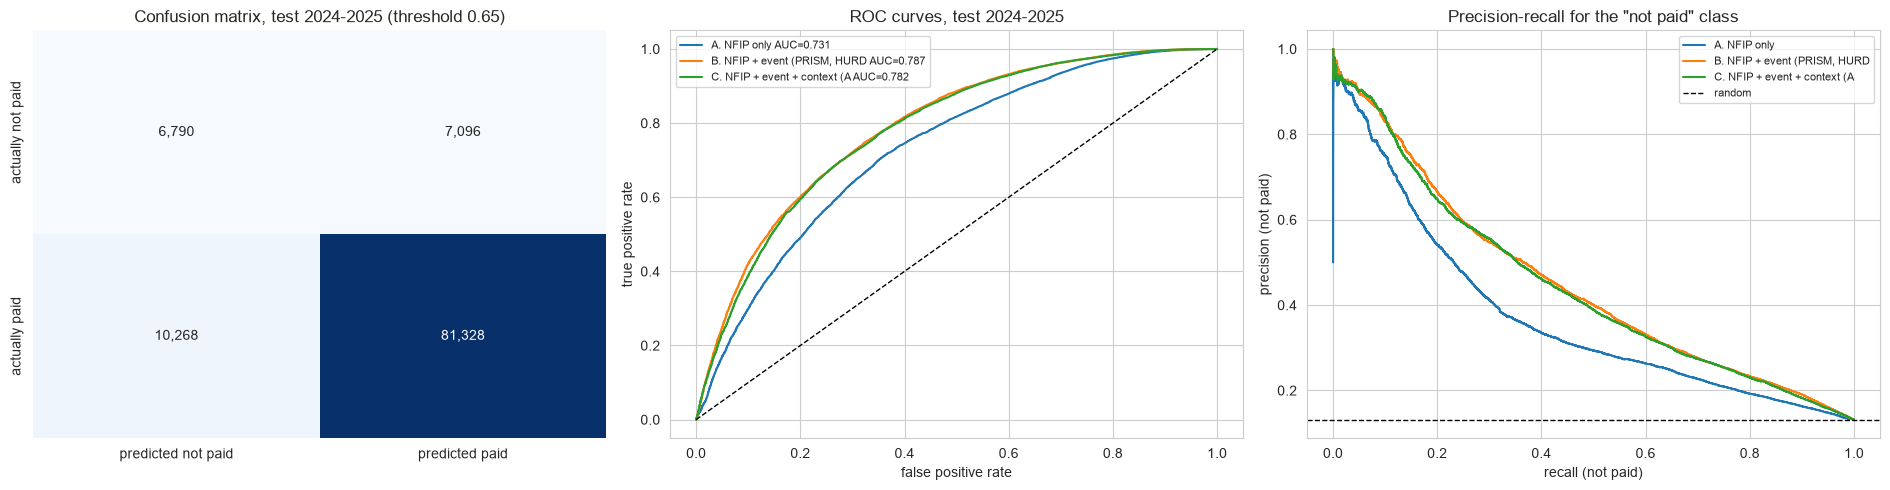

              precision    recall  f1-score   support

    not paid      0.398     0.489     0.439     13886
        paid      0.920     0.888     0.904     91596

    accuracy                          0.835    105482
   macro avg      0.659     0.688     0.671    105482
weighted avg      0.851     0.835     0.842    105482

 threshold_chosen_on_2023  recall_not_paid  precision_not_paid  balanced_accuracy  not_paid_base_rate
                     0.65            0.489              0.3981             0.6884              0.1316


In [19]:
final_scores = progression_scores['C. NFIP + event + context (ACS, NRI)']
final_predictions = (final_scores >= best_threshold).astype(int)
matrix = confusion_matrix(test_claims[TARGET], final_predictions)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(matrix, annot=True, fmt=',', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['predicted not paid', 'predicted paid'], yticklabels=['actually not paid', 'actually paid'])
axes[0].set_title(f'Confusion matrix, test 2024-2025 (threshold {best_threshold})')
for set_name, scores in progression_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(test_claims[TARGET], scores)
    axes[1].plot(false_positive_rate, true_positive_rate, label=f'{set_name[:28]} AUC={roc_auc_score(test_claims[TARGET], scores):.3f}')
    precision, recall, _ = precision_recall_curve(1 - test_claims[TARGET], -scores)
    axes[2].plot(recall, precision, label=f'{set_name[:28]}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('false positive rate')
axes[1].set_ylabel('true positive rate')
axes[1].set_title('ROC curves, test 2024-2025')
axes[1].legend(fontsize=8)
axes[2].axhline(1 - test_claims[TARGET].mean(), color='k', ls='--', lw=1, label='random')
axes[2].set_xlabel('recall (not paid)')
axes[2].set_ylabel('precision (not paid)')
axes[2].set_title('Precision-recall for the "not paid" class')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_confusion_roc_pr.png', dpi=120)
plt.show()
print(classification_report(test_claims[TARGET], final_predictions, target_names=['not paid', 'paid'], digits=3))

operating_point = pd.DataFrame([{
    'threshold_chosen_on_2023': best_threshold,
    'recall_not_paid': ((final_predictions == 0) & (test_claims[TARGET] == 0)).sum() / (test_claims[TARGET] == 0).sum(),
    'precision_not_paid': ((final_predictions == 0) & (test_claims[TARGET] == 0)).sum() / max(1, (final_predictions == 0).sum()),
    'balanced_accuracy': balanced_accuracy_score(test_claims[TARGET], final_predictions),
    'not_paid_base_rate': 1 - test_claims[TARGET].mean()}]).round(4)
operating_point.to_csv(TABLE_DIR / '03_rq1_operating_point.csv', index=False)
print(operating_point.to_string(index=False))

## 12.1 Can we trust the probabilities? Calibration and the Brier score

ROC-AUC only checks the **ranking**. A triage tool also needs probabilities that mean what they say: of all claims
that get "70% paid", about 70% should really be paid. A **reliability curve** puts claims into 10 bins by predicted
probability and plots the mean prediction against the observed paid rate (a perfect model lies on the diagonal).
The **Brier score** is the mean squared error of the probability (lower is better). As a reference we also give the
Brier score of a model that always predicts the training-years paid rate.

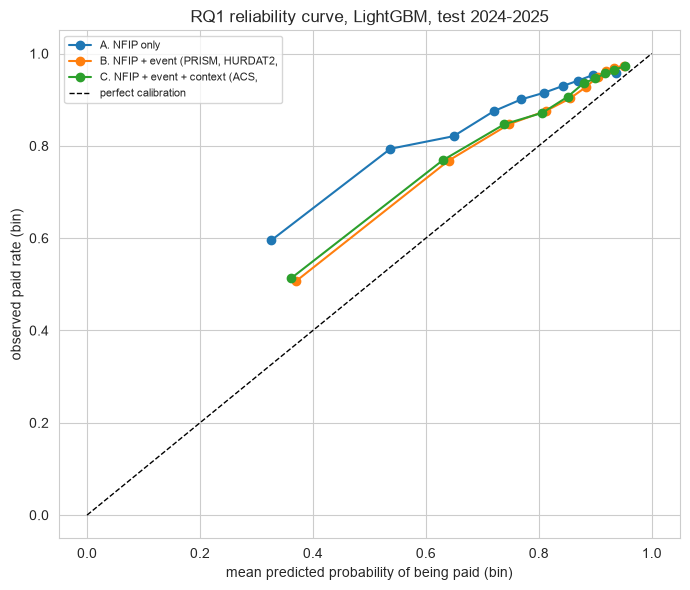

                            feature_set  brier_score  brier_constant_train_rate  mean_predicted_paid  observed_paid_rate  largest_bin_gap
                           A. NFIP only       0.1246                     0.1181               0.7356              0.8684           0.2691
B. NFIP + event (PRISM, HURDAT2, coast)       0.0992                     0.1181               0.8019              0.8684           0.1368
   C. NFIP + event + context (ACS, NRI)       0.1007                     0.1181               0.7972              0.8684           0.1517


In [20]:
calibration_rows = []
fig, ax = plt.subplots(figsize=(7, 6))
training_paid_rate = train_claims[TARGET].mean()
for set_name, scores in progression_scores.items():
    observed_rate, mean_predicted = calibration_curve(test_claims[TARGET], scores, n_bins=10, strategy='quantile')
    ax.plot(mean_predicted, observed_rate, 'o-', label=set_name[:32])
    calibration_rows.append({'feature_set': set_name, 'brier_score': brier_score_loss(test_claims[TARGET], scores),
                             'brier_constant_train_rate': brier_score_loss(test_claims[TARGET], np.full(len(scores), training_paid_rate)),
                             'mean_predicted_paid': scores.mean(), 'observed_paid_rate': test_claims[TARGET].mean(),
                             'largest_bin_gap': np.abs(observed_rate - mean_predicted).max()})
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect calibration')
ax.set_xlabel('mean predicted probability of being paid (bin)')
ax.set_ylabel('observed paid rate (bin)')
ax.set_title('RQ1 reliability curve, LightGBM, test 2024-2025')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_calibration.png', dpi=120)
plt.show()
calibration_table = pd.DataFrame(calibration_rows).round(4)
calibration_table.to_csv(TABLE_DIR / '03_rq1_calibration.csv', index=False)
print(calibration_table.to_string(index=False))

**Reading the calibration.** All three models **under-predict** payment on 2024-2025: the mean predicted paid
probability is 0.74 (A), 0.80 (B) and 0.80 (C), but 86.8% of the test claims were paid. The test years were more
often paid than the training years (Helene rained on almost everyone), and a model cannot know this in advance.
With event data (B) the Brier score is 0.099, clearly better than the constant-rate reference (0.118). The NFIP-only
model (0.125) is even *worse* than the constant, because its probabilities are too low by more than 0.25 in some
bins. So: the **ranking** of B and C is useful, but the probabilities should be **re-calibrated** on the most
recent season before anyone reads them as "x% chance of payment". This is also why the threshold in Section 12 is
chosen on a separate year.

---
# Section 13: Which Features Drive the Prediction? (SHAP)

SHAP splits each prediction into additive contributions, one per feature, using ideas from game
theory (Shapley values). The summary plot shows, for each feature, how high and low values push the
prediction up or down.

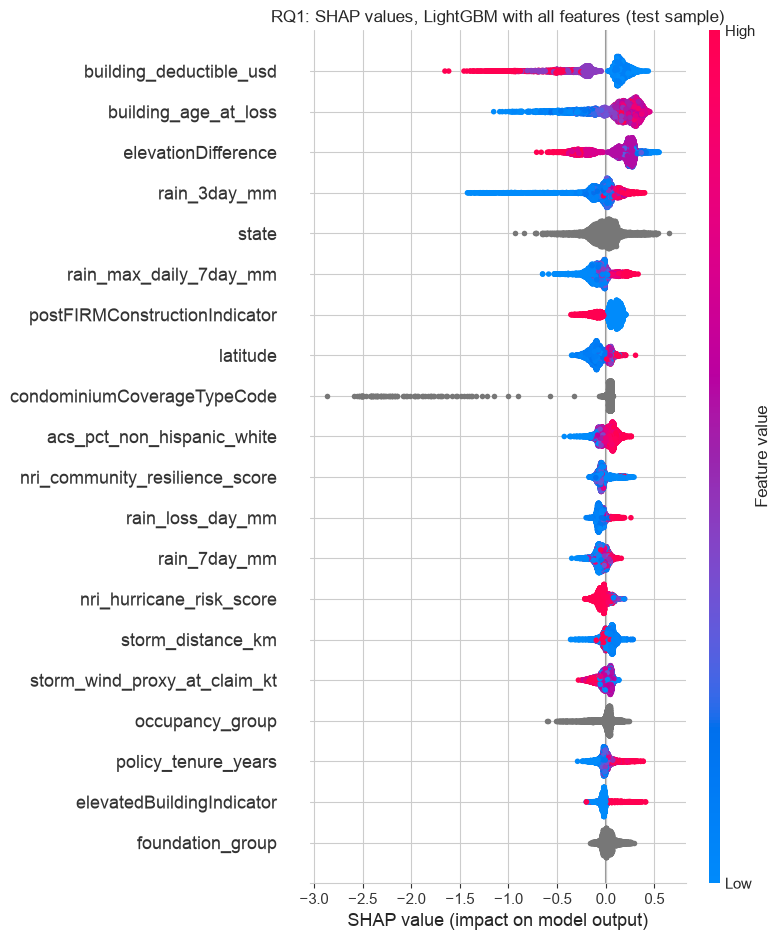

Mean |SHAP| share by data source (%):
NFIP       61.0
context    18.0
event      21.0

Top 12 features:
building_deductible_usd           0.2538
building_age_at_loss              0.2428
elevationDifference               0.2356
rain_3day_mm                      0.1354
state                             0.1093
rain_max_daily_7day_mm            0.1057
postFIRMConstructionIndicator     0.1036
latitude                          0.0931
condominiumCoverageTypeCode       0.0787
acs_pct_non_hispanic_white        0.0689
nri_community_resilience_score    0.0599
rain_loss_day_mm                  0.0573


In [21]:
shap_sample = to_category_frame(test_claims.sample(5000, random_state=SEED), numeric_C, categorical_C)
explainer = shap.TreeExplainer(lightgbm_C)
shap_values = explainer.shap_values(shap_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap.summary_plot(shap_values, shap_sample, max_display=20, show=False)
plt.title('RQ1: SHAP values, LightGBM with all features (test sample)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_shap_summary.png', dpi=110)
plt.show()

shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_sample.columns).sort_values(ascending=False)
shap_by_source = shap_importance.groupby(lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES
                                         else 'event' if c in EVENT_FEATURES else 'context').sum()
print('Mean |SHAP| share by data source (%):')
print((shap_by_source / shap_by_source.sum() * 100).round(1).to_string())
shap_importance.round(4).to_csv(TABLE_DIR / '03_rq1_shap_importance.csv')
print('\nTop 12 features:')
print(shap_importance.head(12).round(4).to_string())

---
# Section 14: Where Does the Model Fail?

In [22]:
test_claims['rq1_score'] = final_scores
error_by_event = (test_claims.groupby('event_group')
                  .apply(lambda g: pd.Series({'claims': len(g), 'paid_rate': g[TARGET].mean(),
                                              'ROC_AUC': roc_auc_score(g[TARGET], g['rq1_score']) if g[TARGET].nunique() == 2 else np.nan}))
                  .sort_values('claims', ascending=False).head(10))
print(error_by_event.round(3).to_string())

                                claims  paid_rate  ROC_AUC
event_group                                               
Hurricane Helene               54363.0      0.916    0.818
Hurricane Milton               19233.0      0.819    0.703
no_named_event_2024             9481.0      0.764    0.744
no_named_event_2025             6014.0      0.806    0.779
Hurricane Beryl                 2318.0      0.657    0.696
Hurricane Debby                 2264.0      0.835    0.701
2025-04-Central U.S.-Flooding   2006.0      0.909    0.709
Hurricane Francine              1994.0      0.873    0.666
June South Florida Flooding     1356.0      0.849    0.701
Texas Spring Flooding           1012.0      0.888    0.695


In [23]:
results_rq1 = {'progression': progression_table.to_dict('records'), 'event_grouped_cv': cv_table.to_dict('records'),
               'threshold': best_threshold, 'model_comparison': comparison_table.to_dict('records')}

---
# Section 15: A Sharper RQ1: Closed Claims, Uncertainty by Storm, and Kinds of Non-Payment

Sections 1-14 answered the initial question. Here we answer the **refined RQ1** (top of the notebook) in three steps:

1. **Split "not paid" by its reason.** `nonPaymentReasonBuilding` is a leaking column, so it is **never a feature**.
   We use it only *after* the model is trained, to understand the errors.
2. **Remove claims that are probably still open**, then compare NFIP-only (A) with NFIP + event (B), and put a
   confidence interval on the gain by resampling whole storms.
3. **Score each kind of non-payment separately** (H2).

## 15.1 What does "not paid" contain?

The FEMA data dictionary gives each reason code a meaning. We group the codes:

| Group | Codes | Meaning |
|---|---|---|
| `no_flood_damage` | 06, 20 | "not actual flood", "no demonstrable damage" |
| `below_deductible` | 01 | the damage was smaller than the deductible |
| `other_or_admin` | 97, 08 | "other", "failure to pursue claim" |
| `excluded_peril` | all other codes | seepage, sewer backup, wind, erosion, ... (not covered by flood insurance) |
| `blank_reason` | (empty) | no payment **and** no reason: most likely the claim is **still open** |

In [24]:
REASON_GROUPS = {'06': 'no_flood_damage', '20': 'no_flood_damage', '01': 'below_deductible',
                 '97': 'other_or_admin', '08': 'other_or_admin'}


def add_reason_group(data):
    reason = data['nonPaymentReasonBuilding']
    return np.where(data[TARGET] == 1, 'paid',
                    np.where(reason.isna(), 'blank_reason', reason.map(REASON_GROUPS).fillna('excluded_peril')))


claims['reason_group'] = add_reason_group(claims)
test_claims['reason_group'] = add_reason_group(test_claims)
unpaid_claims = claims[claims[TARGET] == 0]
reason_share_by_year = (pd.crosstab(unpaid_claims['loss_year'], unpaid_claims['reason_group'], normalize='index') * 100).round(1)
reason_share_by_year.to_csv(TABLE_DIR / '03_rq1_reason_share_by_year.csv')
print('Share of UNPAID claims by reason group, per loss year (%):')
print(reason_share_by_year.to_string())

Share of UNPAID claims by reason group, per loss year (%):
reason_group  below_deductible  blank_reason  excluded_peril  no_flood_damage  other_or_admin
loss_year                                                                                    
2020                      30.1           6.7             3.4             41.6            18.1
2021                      23.9           2.4             2.1             48.9            22.7
2022                      20.5           9.7             2.0             49.3            18.6
2023                      24.5           9.4             1.2             45.1            19.8
2024                      27.0          13.4             1.0             35.1            23.5
2025                      18.0          19.1             1.1             45.8            16.0


**Reading the table.** In 2020-2023 only 2-10% of unpaid claims have no reason. In the test years this share
jumps (2024 and especially 2025). A claim closed without payment always gets a reason, so these are most likely
claims that were **still open** when FEMA exported the file. For them, "not paid" is not yet true. They add noise
to the target exactly in the test years, so the refined question uses **closed claims only**.

## 15.2 H1: does event data help, and how sure are we?

We reuse the LightGBM scores from Section 11 (same models, same 2020-2023 training). The score here is the
probability of **not** being paid.

**Event-block bootstrap.** Claims from one storm are not independent: if the model does well on Helene, it does
well on thousands of Helene claims at once. So we do not resample single claims. We resample **whole events**
(with replacement), recompute the metrics for A and B, and keep the difference B - A. After 500 repeats, the 2.5th
and 97.5th percentiles of the differences give a 95% confidence interval.

In [25]:
test_claims['not_paid'] = 1 - test_claims[TARGET]
test_claims['score_not_paid_A'] = 1 - progression_scores['A. NFIP only']
test_claims['score_not_paid_B'] = 1 - progression_scores['B. NFIP + event (PRISM, HURDAT2, coast)']
closed_test_claims = test_claims[test_claims['reason_group'] != 'blank_reason'].reset_index(drop=True)


def not_paid_metrics(data, score_column):
    return {'ROC_AUC': roc_auc_score(data['not_paid'], data[score_column]),
            'PR_AUC': average_precision_score(data['not_paid'], data[score_column]),
            'lift_top10%': lift_at_top(data['not_paid'].values, data[score_column].values, 0.10)}


h1_rows = []
for version, data in [('all test claims', test_claims), ('closed claims only', closed_test_claims)]:
    for model_name, column in [('A. NFIP only', 'score_not_paid_A'), ('B. NFIP + event', 'score_not_paid_B')]:
        h1_rows.append({'test_set': version, 'claims': len(data), 'not_paid_rate': data['not_paid'].mean(),
                        'model': model_name, **not_paid_metrics(data, column)})
h1_table = pd.DataFrame(h1_rows).round(3)
h1_table.to_csv(TABLE_DIR / '03_rq1_refined_closed_claims.csv', index=False)
print(h1_table.to_string(index=False))

          test_set  claims  not_paid_rate           model  ROC_AUC  PR_AUC  lift_top10%
   all test claims  105482          0.132    A. NFIP only    0.731   0.371        3.075
   all test claims  105482          0.132 B. NFIP + event    0.787   0.449        3.747
closed claims only  103530          0.115    A. NFIP only    0.737   0.352        3.182
closed claims only  103530          0.115 B. NFIP + event    0.793   0.427        3.899


In [26]:
event_rows = closed_test_claims.groupby('event_group').indices
event_names = list(event_rows)
bootstrap_rng = np.random.default_rng(SEED)
bootstrap_differences = []
for repeat in range(500):
    chosen_events = bootstrap_rng.choice(len(event_names), len(event_names), replace=True)
    resampled = closed_test_claims.iloc[np.concatenate([event_rows[event_names[i]] for i in chosen_events])]
    if resampled['not_paid'].nunique() < 2:
        continue
    metrics_A = not_paid_metrics(resampled, 'score_not_paid_A')
    metrics_B = not_paid_metrics(resampled, 'score_not_paid_B')
    bootstrap_differences.append({name: metrics_B[name] - metrics_A[name] for name in metrics_A})
bootstrap_differences = pd.DataFrame(bootstrap_differences)

point_A = not_paid_metrics(closed_test_claims, 'score_not_paid_A')
point_B = not_paid_metrics(closed_test_claims, 'score_not_paid_B')
bootstrap_table = pd.DataFrame([{
    'metric': name, 'NFIP_only_A': point_A[name], 'NFIP_plus_event_B': point_B[name],
    'gain_B_minus_A': point_B[name] - point_A[name],
    'ci_95_low': bootstrap_differences[name].quantile(0.025), 'ci_95_high': bootstrap_differences[name].quantile(0.975),
    'share_of_repeats_with_gain_%': (bootstrap_differences[name] > 0).mean() * 100} for name in point_A]).round(3)
bootstrap_table.to_csv(TABLE_DIR / '03_rq1_refined_bootstrap.csv', index=False)
print(f'Closed test claims: {len(closed_test_claims):,}, events resampled: {len(event_names)}, '
      f'valid repeats: {len(bootstrap_differences)}')
print(bootstrap_table.to_string(index=False))

Closed test claims: 103,530, events resampled: 26, valid repeats: 500
     metric  NFIP_only_A  NFIP_plus_event_B  gain_B_minus_A  ci_95_low  ci_95_high  share_of_repeats_with_gain_%
    ROC_AUC        0.737              0.793           0.056      0.024       0.129                         100.0
     PR_AUC        0.352              0.427           0.075      0.025       0.165                         100.0
lift_top10%        3.182              3.899           0.717      0.243       1.531                         100.0


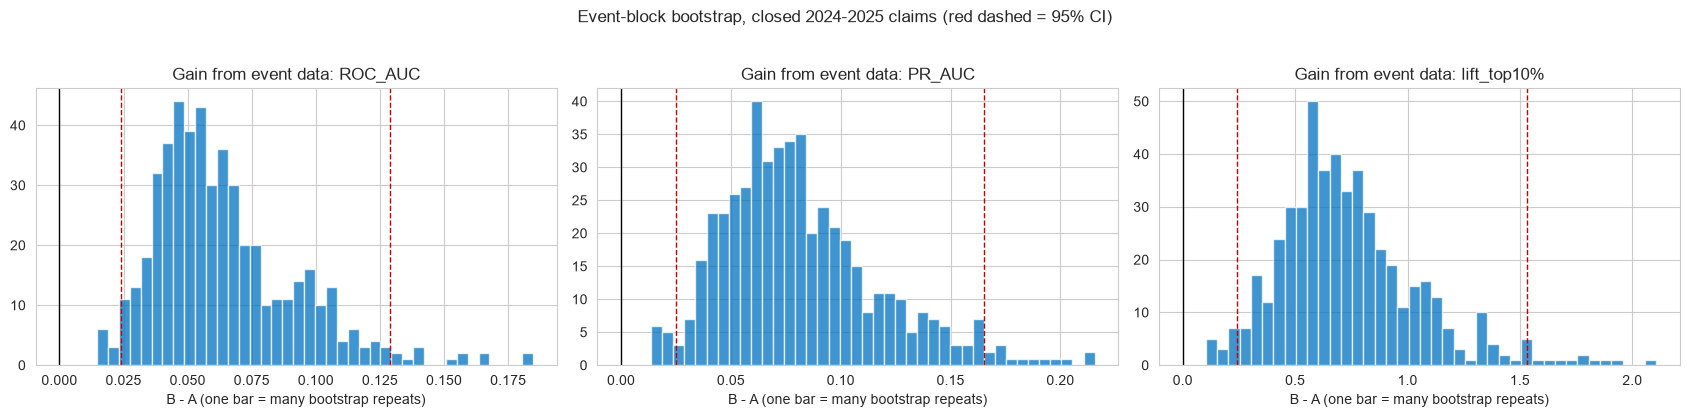

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, ['ROC_AUC', 'PR_AUC', 'lift_top10%']):
    ax.hist(bootstrap_differences[name], bins=40, color='#0070C0', alpha=0.75)
    ax.axvline(0, color='k', lw=1)
    for edge in bootstrap_table.loc[bootstrap_table['metric'] == name, ['ci_95_low', 'ci_95_high']].values[0]:
        ax.axvline(edge, color='#C00000', ls='--', lw=1)
    ax.set_title(f'Gain from event data: {name}')
    ax.set_xlabel('B - A (one bar = many bootstrap repeats)')
plt.suptitle('Event-block bootstrap, closed 2024-2025 claims (red dashed = 95% CI)', y=1.03)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_refined_bootstrap.png', dpi=120, bbox_inches='tight')
plt.show()

**Sensitivity: without Hurricane Helene.** About half of the test claims come from one storm (Helene). Is the gain
only a Helene effect? We repeat the closed-claims comparison and the event-block bootstrap **without Helene**, using
the helper `event_block_bootstrap` from `nfip_project_utils.py`. The rows are added to the two tables above.

In [28]:
no_helene_claims = closed_test_claims[closed_test_claims['event_group'] != 'Hurricane Helene'].reset_index(drop=True)
not_paid_metric_functions = {'ROC_AUC': roc_auc_score, 'PR_AUC': average_precision_score,
                             'lift_top10%': lambda y, s: lift_at_top(y, s, 0.10)}
no_helene_bootstrap = event_block_bootstrap(no_helene_claims, 'not_paid',
                                            {'A': 'score_not_paid_A', 'B': 'score_not_paid_B'},
                                            not_paid_metric_functions, baseline='A', n_repeats=500)
for model_name, column in [('A. NFIP only', 'score_not_paid_A'), ('B. NFIP + event', 'score_not_paid_B')]:
    h1_rows.append({'test_set': 'closed claims, without Helene', 'claims': len(no_helene_claims),
                    'not_paid_rate': no_helene_claims['not_paid'].mean(), 'model': model_name,
                    **not_paid_metrics(no_helene_claims, column)})
h1_table = pd.DataFrame(h1_rows).round(3)
h1_table.to_csv(TABLE_DIR / '03_rq1_refined_closed_claims.csv', index=False)

no_helene_rows = []
for metric in not_paid_metric_functions:
    a_row = no_helene_bootstrap[(no_helene_bootstrap['metric'] == metric) & (no_helene_bootstrap['model'] == 'A')].iloc[0]
    b_row = no_helene_bootstrap[(no_helene_bootstrap['metric'] == metric) & (no_helene_bootstrap['model'] == 'B')].iloc[0]
    no_helene_rows.append({'metric': metric, 'NFIP_only_A': a_row['value'], 'NFIP_plus_event_B': b_row['value'],
                           'gain_B_minus_A': b_row['gain_vs_baseline'], 'ci_95_low': b_row['ci_95_low'],
                           'ci_95_high': b_row['ci_95_high'], 'share_of_repeats_with_gain_%': b_row['share_of_repeats_with_gain_%'],
                           'test_set': 'closed claims, without Helene'})
bootstrap_table['test_set'] = bootstrap_table.get('test_set', 'closed claims')
bootstrap_table = pd.concat([bootstrap_table[bootstrap_table['test_set'] == 'closed claims'],
                             pd.DataFrame(no_helene_rows)], ignore_index=True).round(3)
bootstrap_table.to_csv(TABLE_DIR / '03_rq1_refined_bootstrap.csv', index=False)
print(f'Closed test claims without Helene: {len(no_helene_claims):,} in {no_helene_claims["event_group"].nunique()} event groups')
print(h1_table.to_string(index=False))
print()
print(bootstrap_table.to_string(index=False))

Closed test claims without Helene: 49,786 in 25 event groups
                     test_set  claims  not_paid_rate           model  ROC_AUC  PR_AUC  lift_top10%
              all test claims  105482          0.132    A. NFIP only    0.731   0.371        3.075
              all test claims  105482          0.132 B. NFIP + event    0.787   0.449        3.747
           closed claims only  103530          0.115    A. NFIP only    0.737   0.352        3.182
           closed claims only  103530          0.115 B. NFIP + event    0.793   0.427        3.899
closed claims, without Helene   49786          0.161    A. NFIP only    0.641   0.285        2.053
closed claims, without Helene   49786          0.161 B. NFIP + event    0.730   0.396        2.958

     metric  NFIP_only_A  NFIP_plus_event_B  gain_B_minus_A  ci_95_low  ci_95_high  share_of_repeats_with_gain_%                      test_set
    ROC_AUC        0.737              0.793           0.056      0.024       0.129                    

**Reading the Helene check.** Without Helene, 49,786 closed claims in 25 event groups remain. Both models are weaker
there (NFIP-only ROC-AUC 0.64, with event data 0.73), but the **gain from event data is larger**: +0.089 ROC-AUC
[95% CI +0.045, +0.148] and +0.111 PR-AUC [+0.047, +0.185]. So the main result is not a Helene effect.

## 15.3 H2: which kind of non-payment can be predicted?

For each reason group we compute the ROC-AUC of **that group against paid claims** (other unpaid claims are left
out). We also ask: of all claims in the group, what share lands in the **top 10% of scores** of model B? For paid
claims this share should be small.

In [29]:
paid_test_claims = test_claims[test_claims['reason_group'] == 'paid']
top_10_percent_cut = np.quantile(test_claims['score_not_paid_B'], 0.90)
reason_rows = []
for group in ['below_deductible', 'no_flood_damage', 'other_or_admin', 'excluded_peril', 'blank_reason', 'paid']:
    group_claims = test_claims[test_claims['reason_group'] == group]
    row = {'reason_group': group, 'claims': len(group_claims),
           'share_in_top10%_B': (group_claims['score_not_paid_B'] >= top_10_percent_cut).mean(),
           'median_rain_3day_mm': group_claims['rain_3day_mm'].median()}
    if group != 'paid':
        versus_paid = pd.concat([group_claims, paid_test_claims])
        row['ROC_AUC_A'] = roc_auc_score(versus_paid['not_paid'], versus_paid['score_not_paid_A'])
        row['ROC_AUC_B'] = roc_auc_score(versus_paid['not_paid'], versus_paid['score_not_paid_B'])
        row['gain_B_minus_A'] = row['ROC_AUC_B'] - row['ROC_AUC_A']
    reason_rows.append(row)
reason_table = pd.DataFrame(reason_rows).round(3)
reason_table.to_csv(TABLE_DIR / '03_rq1_refined_by_reason.csv', index=False)
print(reason_table.to_string(index=False))

    reason_group  claims  share_in_top10%_B  median_rain_3day_mm  ROC_AUC_A  ROC_AUC_B  gain_B_minus_A
below_deductible    3597              0.375               72.358      0.758      0.804           0.046
 no_flood_damage    5057              0.344               81.203      0.721      0.792           0.071
  other_or_admin    3134              0.445               63.015      0.738      0.782           0.044
  excluded_peril     146              0.274               77.409      0.710      0.787           0.077
    blank_reason    1952              0.348               65.416      0.696      0.750           0.055
            paid   91596              0.058               63.015        NaN        NaN             NaN


## 15.4 A check: is the rain pattern the same in training and test years?

Section 3.1 found that unpaid claims usually had **little** rain. If that pattern changed in 2024-2025, the model
must be relying on other features there. We compare the median 3-day rain by reason group and period.

In [30]:
claims['period'] = np.where(claims['loss_year'].isin(TRAIN_YEARS), 'train 2020-2023', 'test 2024-2025')
rain_by_reason = claims.pivot_table(index='reason_group', columns='period', values='rain_3day_mm', aggfunc='median').round(1)
print('Median 3-day rain (mm) by reason group and period:')
print(rain_by_reason.to_string())
helene_share = (test_claims['event_group'] == 'Hurricane Helene').mean() * 100
print(f'\nShare of 2024-2025 test claims from Hurricane Helene: {helene_share:.1f}%')
rain_by_reason.to_csv(TABLE_DIR / '03_rq1_rain_by_reason_period.csv')

# Paid rate for claims with little rain (< 40 mm in 3 days) and the rest, in each period
claims['rain_band'] = np.where(claims['rain_3day_mm'] < 40, 'little rain (< 40 mm)', 'more rain (>= 40 mm)')
paid_by_rain_band = claims.pivot_table(index='rain_band', columns='period', values=TARGET, aggfunc='mean').round(3)
claims_by_rain_band = claims.pivot_table(index='rain_band', columns='period', values=TARGET, aggfunc='size')
print('\nPaid rate by rain band and period:')
print(paid_by_rain_band.to_string())
print('\nNumber of claims by rain band and period:')
print(claims_by_rain_band.to_string())
paid_by_rain_band.to_csv(TABLE_DIR / '03_rq1_paid_by_rain_band.csv')

Median 3-day rain (mm) by reason group and period:
period            test 2024-2025  train 2020-2023
reason_group                                     
below_deductible            72.4            148.1
blank_reason                65.4            141.2
excluded_peril              77.4            141.5
no_flood_damage             81.2            148.1
other_or_admin              63.0            144.3
paid                        63.0            159.1

Share of 2024-2025 test claims from Hurricane Helene: 51.5%

Paid rate by rain band and period:
period                 test 2024-2025  train 2020-2023
rain_band                                             
little rain (< 40 mm)           0.675            0.602
more rain (>= 40 mm)            0.881            0.829

Number of claims by rain band and period:
period                 test 2024-2025  train 2020-2023
rain_band                                             
little rain (< 40 mm)            6522            14560
more rain (>= 40 mm)    

**Reading the rain check: the pattern reverses in the test years.** In 2020-2023 paid claims had **more** rain than
unpaid ones (median 159 mm against 141-148 mm for every non-payment group). In 2024-2025 the order **reverses**: paid
claims had a median of only 63 mm, while "no flood damage" claims had 81 mm, excluded perils 77 mm and "below
deductible" 72 mm. The reason is Hurricane Helene: 51.5% of the test claims come from Helene, which brought heavy
rain to almost everyone in its path, so the median no longer separates paid and unpaid claims.

The signal did not disappear; it moved to the **low-rain tail**. Claims with little rain (< 40 mm in 3 days) are paid
60% of the time in training and 68% in testing, against 83% and 88% for the other claims. Tree-based models use
exactly this kind of threshold, not the median, which is why event data still helps in the test years (Section 15.2).

In [31]:
results_rq1['refined'] = {'reason_share_by_year': reason_share_by_year.reset_index().to_dict('records'),
                          'closed_claims': h1_table.to_dict('records'), 'bootstrap': bootstrap_table.to_dict('records'),
                          'by_reason': reason_table.to_dict('records')}
json.dump(results_rq1, open(TABLE_DIR / '03_rq1_results.json', 'w'), indent=2, default=float)

---
## The numbers behind the answer

The cell below reads the key numbers back from the saved tables (`tables/03_*.csv`). The answer text uses these
numbers, rounded. If the data changes, rerun the notebook and compare the text with this table.

In [32]:
progression_saved = pd.read_csv(TABLE_DIR / '03_rq1_progression.csv').set_index('feature_set')
cv_saved = pd.read_csv(TABLE_DIR / '03_rq1_event_grouped_cv.csv').set_index('feature_set')
models_saved = pd.read_csv(TABLE_DIR / '03_rq1_model_comparison.csv').set_index('model')
closed_saved = pd.read_csv(TABLE_DIR / '03_rq1_refined_closed_claims.csv')
bootstrap_saved = pd.read_csv(TABLE_DIR / '03_rq1_refined_bootstrap.csv')
reasons_saved = pd.read_csv(TABLE_DIR / '03_rq1_refined_by_reason.csv').set_index('reason_group')
reason_share_saved = pd.read_csv(TABLE_DIR / '03_rq1_reason_share_by_year.csv').set_index('loss_year')
ablation_saved = pd.read_csv(TABLE_DIR / '03_rq1_ablation.csv').set_index('feature_set')
calibration_saved = pd.read_csv(TABLE_DIR / '03_rq1_calibration.csv').set_index('feature_set')
operating_saved = pd.read_csv(TABLE_DIR / '03_rq1_operating_point.csv').iloc[0]
rain_saved = pd.read_csv(TABLE_DIR / '03_rq1_rain_by_reason_period.csv').set_index('reason_group')
shap_saved = pd.read_csv(TABLE_DIR / '03_rq1_shap_importance.csv', index_col=0).iloc[:, 0]
shap_source = shap_saved.groupby(lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES
                                 else 'event' if c in EVENT_FEATURES else 'context').sum()
shap_source = shap_source / shap_source.sum() * 100
set_A, set_B, set_C = progression_saved.index[0], progression_saved.index[1], progression_saved.index[2]


def boot(metric, test_set='closed claims'):
    return bootstrap_saved[(bootstrap_saved['metric'] == metric) & (bootstrap_saved['test_set'] == test_set)].iloc[0]


def closed(test_set, model):
    return closed_saved[(closed_saved['test_set'] == test_set) & (closed_saved['model'] == model)].iloc[0]


rows = [
    ('test claims 2024-2025 (all)', int(closed('all test claims', 'A. NFIP only')['claims']), '03_rq1_refined_closed_claims'),
    ('not-paid rate, all test claims', closed('all test claims', 'A. NFIP only')['not_paid_rate'], '03_rq1_refined_closed_claims'),
    ('closed test claims', int(closed('closed claims only', 'A. NFIP only')['claims']), '03_rq1_refined_closed_claims'),
    ('not-paid rate, closed claims', closed('closed claims only', 'A. NFIP only')['not_paid_rate'], '03_rq1_refined_closed_claims'),
    ('unpaid with blank reason, % of unpaid, 2024', reason_share_saved.loc[2024, 'blank_reason'], '03_rq1_reason_share_by_year'),
    ('unpaid with blank reason, % of unpaid, 2025', reason_share_saved.loc[2025, 'blank_reason'], '03_rq1_reason_share_by_year'),
    ('unpaid with blank reason, % of unpaid, max 2020-2023', reason_share_saved.loc[2020:2023, 'blank_reason'].max(), '03_rq1_reason_share_by_year'),
    ('ROC-AUC all test claims A / B', f"{closed('all test claims', 'A. NFIP only')['ROC_AUC']:.3f} / {closed('all test claims', 'B. NFIP + event')['ROC_AUC']:.3f}", '03_rq1_refined_closed_claims'),
]
for metric in ['ROC_AUC', 'PR_AUC', 'lift_top10%']:
    for test_set in ['closed claims', 'closed claims, without Helene']:
        b = boot(metric, test_set)
        rows.append((f'{metric} {test_set}: A -> B, gain [95% CI]',
                     f"{b['NFIP_only_A']:.3f} -> {b['NFIP_plus_event_B']:.3f}, {b['gain_B_minus_A']:+.3f} [{b['ci_95_low']:+.3f}, {b['ci_95_high']:+.3f}], "
                     f"gain in {b['share_of_repeats_with_gain_%']:.0f}% of repeats", '03_rq1_refined_bootstrap'))
rows.append(('closed claims without Helene', int(closed('closed claims, without Helene', 'A. NFIP only')['claims']), '03_rq1_refined_closed_claims'))
for group in ['below_deductible', 'no_flood_damage', 'other_or_admin', 'excluded_peril', 'blank_reason', 'paid']:
    r = reasons_saved.loc[group]
    text = f"claims {int(r['claims']):,}, top-10% share {r['share_in_top10%_B'] * 100:.1f}%"
    if group != 'paid':
        text += f", ROC A -> B {r['ROC_AUC_A']:.3f} -> {r['ROC_AUC_B']:.3f}"
    rows.append((f'reason group {group}', text, '03_rq1_refined_by_reason'))
for name, set_name in [('A', set_A), ('B', set_B), ('C', set_C)]:
    rows.append((f'LightGBM time split {name}: ROC / PR-AUC not paid',
                 f"{progression_saved.loc[set_name, 'LightGBM_ROC_AUC']:.3f} / {progression_saved.loc[set_name, 'LightGBM_PR_AUC_not_paid']:.3f}", '03_rq1_progression'))
for set_name in cv_saved.index:
    rows.append((f'event-grouped CV ROC {set_name[:2]}', f"{cv_saved.loc[set_name, 'mean_ROC_AUC']:.3f} +/- {cv_saved.loc[set_name, 'std']:.3f}", '03_rq1_event_grouped_cv'))
rows.append(('course models ROC-AUC', ', '.join(f'{m}: {v:.3f}' for m, v in models_saved['ROC_AUC'].items()), '03_rq1_model_comparison'))
for set_name in ablation_saved.index[2:]:
    rows.append((f'ablation: {set_name}, ROC / PR change vs full B',
                 f"{ablation_saved.loc[set_name, 'ROC_change_vs_full_B']:+.3f} / {ablation_saved.loc[set_name, 'PR_change_vs_full_B']:+.3f}", '03_rq1_ablation'))
for set_name in calibration_saved.index:
    rows.append((f'Brier score {set_name[:2]} (constant-rate reference)',
                 f"{calibration_saved.loc[set_name, 'brier_score']:.4f} ({calibration_saved.loc[set_name, 'brier_constant_train_rate']:.4f}), largest bin gap {calibration_saved.loc[set_name, 'largest_bin_gap']:.3f}",
                 '03_rq1_calibration'))
rows += [
    ('threshold chosen on 2023', operating_saved['threshold_chosen_on_2023'], '03_rq1_operating_point'),
    ('recall / precision not paid at that threshold', f"{operating_saved['recall_not_paid']:.3f} / {operating_saved['precision_not_paid']:.3f}", '03_rq1_operating_point'),
    ('balanced accuracy at that threshold', operating_saved['balanced_accuracy'], '03_rq1_operating_point'),
    ('SHAP share NFIP / event / context %', f"{shap_source.get('NFIP', 0):.0f} / {shap_source.get('event', 0):.0f} / {shap_source.get('context', 0):.0f}", '03_rq1_shap_importance'),
    ('top 5 SHAP features', ', '.join(shap_saved.index[:5]), '03_rq1_shap_importance'),
    ('median 3-day rain train: paid / no_flood_damage', f"{rain_saved.loc['paid', 'train 2020-2023']} / {rain_saved.loc['no_flood_damage', 'train 2020-2023']}", '03_rq1_rain_by_reason_period'),
    ('median 3-day rain test: paid / no_flood_damage', f"{rain_saved.loc['paid', 'test 2024-2025']} / {rain_saved.loc['no_flood_damage', 'test 2024-2025']}", '03_rq1_rain_by_reason_period'),
]
answer_numbers = show_answer_numbers(rows, '03_rq1')

                                                        quantity                                                                                                                                                                                                    value                       source
                                     test claims 2024-2025 (all)                                                                                                                                                                                                   105482 03_rq1_refined_closed_claims
                                  not-paid rate, all test claims                                                                                                                                                                                                    0.132 03_rq1_refined_closed_claims
                                              closed test claims                                                   

---
# Research Question -> Answer

> **RQ1 (refined). Among closed NFIP claims, do flood-hazard facts known at filing time (PRISM rain, HURDAT2 storm,
> coast distance) improve the prediction of a claim closing without building payment, beyond building and policy
> facts alone? And which kinds of non-payment can be predicted?**

**Answer: yes. Event data gives a clear gain, and the gain holds when whole storms are resampled and when Hurricane
Helene is removed. The model is a useful triage tool, not a payment decision.** (All numbers below come from the
`answer_numbers` table printed above.)

**H1 (event data helps): supported.** Closed 2024-2025 claims (103,530; 11.5% not paid), LightGBM:

| Metric | NFIP only (A) | + event data (B) | Gain B - A [95% CI, event-block bootstrap] |
|---|---|---|---|
| ROC-AUC | 0.737 | **0.793** | +0.056 [+0.024, +0.129] |
| PR-AUC "not paid" (random = 0.115) | 0.352 | **0.427** | +0.075 [+0.025, +0.165] |
| Lift in the top 10% | 3.18 | **3.90** | +0.72 [+0.24, +1.53] |

All three intervals are above 0, and the gain was positive in (almost) 100% of the 500 repeats. The intervals are
wide, because the test years hold only 26 event groups.

**Sensitivity without Hurricane Helene** (49,786 closed claims, 25 event groups): ROC-AUC 0.641 -> 0.730, gain
+0.089 [+0.045, +0.148]; PR-AUC 0.285 -> 0.396, gain +0.111 [+0.047, +0.185]. The gain is even larger outside Helene.

**Which outside source?** (ablation, Section 11.2) Removing storm data costs the most ROC-AUC (-0.041), removing rain
costs the most PR-AUC for "not paid" (-0.048); coast distance adds almost nothing (-0.005) beyond lat/lon and zone.

**H2 (flood-driven non-payment is easier to predict): only weakly supported.** Each reason group vs paid claims:

| Reason group | Claims | ROC-AUC A -> B | Share in top 10% of scores (B) |
|---|---|---|---|
| below deductible | 3,597 | 0.758 -> **0.804** | 37.5% |
| no flood damage ("not actual flood", "no demonstrable damage") | 5,057 | 0.721 -> **0.792** | 34.4% |
| other / admin | 3,134 | 0.738 -> 0.782 | 44.5% |
| excluded peril | 146 | 0.710 -> 0.787 | 27.4% |
| (paid claims) | 91,596 | - | 5.8% |

"Below deductible" and "no flood damage" are the easiest to predict and gain the most from event data (+0.05 and
+0.07). But admin closures are almost as predictable, and they take the largest share of the top 10%. So the model is
not only reading "how much did it rain": building and policy facts (deductible, building age, elevation) push every
kind of non-payment up.

**Supporting evidence from Sections 1-14** (all 105,482 test claims, initial question):

| Evidence | NFIP only (A) | + event data (B) | + ACS/NRI context (C) |
|---|---|---|---|
| LightGBM ROC-AUC, time split | 0.731 | **0.787** | 0.782 |
| LightGBM PR-AUC "not paid" (random = 0.132) | 0.371 | **0.449** | 0.444 |
| Event-grouped 5-fold CV ROC-AUC (2020-2023) | 0.671 +/- 0.048 | - | 0.728 +/- 0.019 |

- **Open claims.** Unpaid claims with no reason grow from 2-10% (2020-2023) to 13.4% (2024) and 19.1% (2025). They
  are most likely still open. Removing them changes ROC-AUC by less than 0.01, so the earlier results were not biased.
- **Rain.** The small tree's first split is 3-day rain (<= 48 mm). Claims with less than 40 mm are paid 60% of the
  time in 2020-2023 (68% in 2024-2025), against 83% (88%) above it. In the test years the *median* pattern even
  reverses (paid 63 mm, "no flood damage" 81 mm, against 159 mm and 148 mm in training), because 51.5% of test claims
  come from Helene, which rained on almost everyone. The signal is in the low-rain tail, not in the median
  (Section 15.4).
- **ACS/NRI context does not help on the time split** (0.782 vs 0.787). It helps the event-grouped CV and makes it
  more stable, but neighbourhood values partly act as location IDs (notebook 02).
- **Course models** (set C): tree 0.706, naive Bayes 0.622, k-NN 0.695, logistic 0.689, SVM 0.696, MLP 0.771,
  LightGBM 0.774. The MLP comes close to LightGBM but does not beat it.
- **Operating point:** a threshold of 0.65 chosen on 2023 (with a separate model trained on 2020-2022) gives, on
  2024-2025 with the main 2020-2023 model, recall 0.49 and precision 0.40 for "not paid" (3x the base rate), and
  balanced accuracy 0.69.
- **Calibration:** with event data the Brier score is 0.099 (constant-rate reference 0.118), but all models
  under-predict payment in the test years (mean prediction 0.80 vs 86.8% paid). Use the ranking, and re-calibrate the
  probabilities on a recent season before reading them as chances.
- **SHAP:** 61% NFIP, 21% event, 18% context. Top drivers: deductible, building age, elevation difference, 3-day
  rain, state.
- **Per event:** ROC 0.82 on Helene, but 0.67-0.78 on the other large events. Each storm behaves differently.
- **Why not higher:** 44% of the SVM training claims are support vectors, so the classes overlap a lot. Every kind
  of non-payment scores between 0.78 and 0.80: what decides payment happened inside the house, which we cannot
  know at filing time without leakage.
- **Practical reading:** route the top-scored claims to a faster desk review (3.9 times more unpaid claims there than
  on average). The model cannot replace the adjuster.